Import libraries

In [1]:
import os
import sys
import copy
import time
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib as jl
threads = 4

from tqdm.notebook import tqdm
from functions import *

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import ticker
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
# %matplotlib notebook

# # Use custom style
# # See: https://matplotlib.org/1.5.3/users/style_sheets.html
# style_name = 'paper_1column'
# mpl.style.use(
#     os.environ['WORKSPACE_PATH'] \
#         + '/RESEARCH/styles/matplotlib/' \
#         + style_name + '.mplstyle'
# )

In [3]:
T = 10000
frames = 100

cwd = os.getcwd()
figs = cwd + f'/figs_T{T}K'
try:
    os.mkdir(figs)
except:
    pass

Define paths

In [4]:
sts_fld = cwd + f'/../../isothermal/O3/nestedTimescales/postprocess/CG-DeepONet/src/sts_cg_park/T{T}K'
sts_file = sts_fld + '/sts/excit_diss/output_box/box.dat'
pop_file = sts_fld + '/sts/excit_diss/output_box/pop_O2.dat'
lev_file = '/home/zanardi/WORKSPACE/database/levels/O2.csv'

Manipulate energy levels

In [5]:
lev_dtb = pd.read_csv(lev_file)
lev_dtb['EVib'] = lev_dtb['EVib'] - np.amin(lev_dtb['EVib'])
lev_dtb['ERot'] = lev_dtb['ERot'] - np.amin(lev_dtb['ERot'])
lev_dtb['E'] = lev_dtb['EVib'] + lev_dtb['ERot']
lev_dtb['g'] = 3./2.*(2.*lev_dtb['jqn'] + 1.)
n_lev = len(lev_dtb['g'])
lev_dtb = lev_dtb.sort_values(by='E')

Get StS solution

In [6]:
# Solution from StS
data = pd.read_csv(sts_file, sep="  ", header=1, engine='python')
t = data[[col for col in data.columns if 't' in col]].to_numpy()
n_ov_g = get_n_ov_g(instants=len(data), file=pop_file, n_lev=n_lev)

  0%|          | 0/1421 [00:00<?, ?it/s]

3D animation

  0%|          | 0/3 [00:00<?, ?it/s]

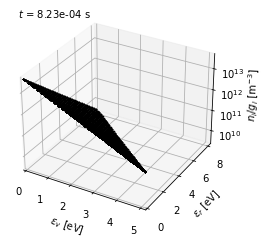

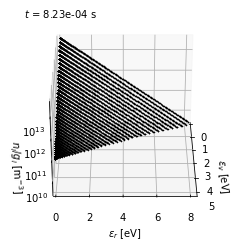

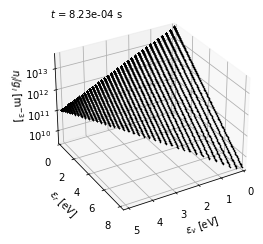

In [7]:
for i, axim in enumerate(tqdm([-60,0,60])):
    # Create animation
    anim = get_3D_animation(
        t_vec=t,
        n_ov_g=n_ov_g,
        frames=frames,
        axim=axim,
        lev_dtb=lev_dtb
    )
    # Save animation
    anim.save(f'{figs}/3DView_{i}.mp4', fps=frames/10, dpi=600)
#     # Display animation
#     HTML(anim.to_jshtml())

OLS surface fitting

In [8]:
# Construct X matrix
x = lev_dtb['EVib'], lev_dtb['ERot']
order = 3

X = []
poly_indices = []
for i in range(order+1):
    for j in range(order-i+1):
        c = i+j if i != 0 and j != 0 else 1
        poly_indices.append([j,i])
        X.append(c * x[0]**j * x[1]**i)
        
poly_indices = np.array(poly_indices)
X = np.stack(X, axis=1)

X_tr = np.transpose(X)
X_inv = np.linalg.inv(np.matmul(X_tr,X))

ols = get_ols_fitting(X)

  0%|          | 0/3 [00:00<?, ?it/s]

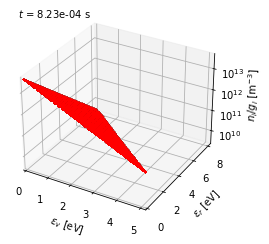

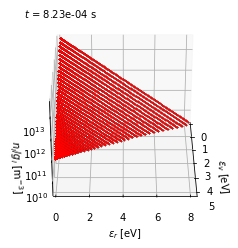

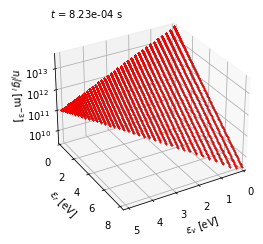

In [9]:
for i, axim in enumerate(tqdm([-60,0,60])):
    # Create animation
    anim = get_3D_animation(
        t_vec=t,
        n_ov_g=n_ov_g,
        frames=frames,
        axim=axim,
        lev_dtb=lev_dtb,
        ols=ols
    )
    # Save animation
    anim.save(f'{figs}/3DView_fit_{i}.mp4', fps=frames/10, dpi=600)
#     # Display animation
#     HTML(anim.to_jshtml())

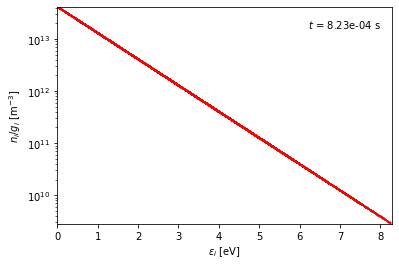

In [10]:
# Create animation
anim = get_2D_animation(
    t_vec=t,
    n_ov_g=n_ov_g,
    frames=frames,
    ols=ols,
    lev_dtb=lev_dtb
)
# Save animation
anim.save(f'{figs}/2DView.mp4', fps=frames/10, dpi=600)
# # Display animation
# HTML(anim.to_jshtml())

Polynomial coefficients time evolution

In [11]:
frames = 1000

w, t_vec= [], []
for frame in tqdm(range(frames)):
    idx = int(frame/frames*len(t))
    t_vec.append(t[idx])
    Y = np.matmul(X_tr, np.log(1./n_ov_g[idx]).reshape(-1,1))
    w.append(np.matmul(X_inv, Y).T)

w = np.vstack(w)
t_vec = np.concatenate(t_vec)
poly_orders = np.sum(poly_indices, axis=1)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [12]:
titles = ['0-th', '1-st', '2-nd', '3-rd']
for o in range(order+1):
    pos = np.where(poly_orders == o)[0]
    indices = poly_indices[pos]
    legend = [r'$\theta_{%s%s}$' % (i,j) for i,j in indices]
    fig, ax = plt.subplots()
    ax.set_ylabel(r'$\theta$')
    ax.set_xscale('log')
    ax.set_xlabel(r'$t$ [s]')
    ax.set_title(f'{titles[o]} order')
    plt.plot(t_vec, w[:,np.where(poly_orders == o)[0]])
    plt.legend(legend)
    plt.savefig(f'{figs}/{o}_order_coeff.pdf', dpi=600)
    plt.close()